## 1. State awal


In [52]:
import os
import urllib.request
import numpy as np
import random
import math
import time
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

SEED = 42
random.seed(SEED)
np.random.seed(SEED)


plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})
WARNA = {"utama": "#2E86AB", "aksen": "#E4572E", "hijau": "#3FA34D", "abu": "#8D99AE"}

## 2. Dataset

Dataset terdiri dari dua berkas:

- `usp1e.xlsx` : daftar ujian (ID ujian dan jumlah peserta).
- `usp1s.xlsx` : daftar mahasiswa; setiap baris berisi ID ujian yang diikuti satu mahasiswa.

Dari data tersebut ditemukan konflik jadwal berukuran `n_exams × n_exams`:

> `conflict[i][j]` = jumlah mahasiswa yang mengikuti **ujian i dan ujian j sekaligus**.

Jika kedua ujian itu ditempatkan di slot yang sama, sebanyak `conflict[i][j]` mahasiswa akan bentrok. Nilai 0 berarti kedua ujian aman ditempatkan di slot yang sama.`NUM_SLOTS` adalah jumlah slot waktu yang tersedia.

In [53]:

BASE_URL = "https://raw.githubusercontent.com/ravneil/exam-timetable-dataset/main/"

for f in ["usp1e.xlsx", "usp1s.xlsx"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE_URL + f, f)
        print(f"Diunduh : {f}")
    else:
        print(f"Sudah ada : {f}")

exams = pd.read_excel("usp1e.xlsx", header=None, names=["exam_id", "n_students"])
students = pd.read_excel("usp1s.xlsx", header=None)

exam_ids = exams["exam_id"].astype(int).tolist()
exam_index = {e: i for i, e in enumerate(exam_ids)}

Sudah ada : usp1e.xlsx
Sudah ada : usp1s.xlsx


In [54]:

n_total = len(exam_ids)
conflict = np.zeros((n_total, n_total), dtype=np.int64)

for row in students.values:

    ujian_mhs = [exam_index[int(v)] for v in row if not pd.isna(v)]


    for a in range(len(ujian_mhs)):
        for b in range(a + 1, len(ujian_mhs)):
            conflict[ujian_mhs[a], ujian_mhs[b]] += 1
            conflict[ujian_mhs[b], ujian_mhs[a]] += 1

NUM_SLOTS = 20
try:
    n_exams = conflict.shape[0]
    print(f"Berhasil memuat matriks konflik. Jumlah ujian (n_exams): {n_exams}")
except NameError:
    print("PERINGATAN: Variabel 'conflict' belum didefinisikan! Silakan muat data matriks konflik Anda terlebih dahulu di sel ini.")
    n_exams = 0

Berhasil memuat matriks konflik. Jumlah ujian (n_exams): 403


### Profil dataset


In [55]:
n_pasangan = int((conflict > 0).sum() // 2)
total_bobot = int(conflict.sum() // 2)

profil = pd.DataFrame({
    "Keterangan": [
        "Jumlah ujian",
        "Jumlah mahasiswa",
        "Total pendaftaran ujian (dari data mahasiswa)",
        "Pasangan ujian yang berpotensi konflik",
        "Total bobot konflik semua pasangan",
        "Kepadatan graf konflik",
        "Jumlah slot waktu (NUM_SLOTS)",
    ],
    "Nilai": [
        f"{n_exams}",
        f"{len(students):,}",
        f"{int(students.notna().sum().sum()):,}",
        f"{n_pasangan:,}",
        f"{total_bobot:,}",
        f"{n_pasangan / (n_exams * (n_exams - 1) / 2):.1%}",
        f"{NUM_SLOTS}",
    ],
})
display(profil)





,Keterangan,Nilai
0,Jumlah ujian,403
1,Jumlah mahasiswa,"18,835"
2,Total pendaftaran ujian (dari data mahasiswa),"47,046"
3,Pasangan ujian yang berpotensi konflik,"5,016"
4,Total bobot konflik semua pasangan,"48,280"
5,Kepadatan graf konflik,6.2%
6,Jumlah slot waktu (NUM_SLOTS),20


## 3. Pemodelan Masalah

Pertama kita memodelkan masalah ini terlebih dahulu sebelum masuk ke perhitungan dan dijalankan oleh algoritma

### 3.1 Membuat jadwal acak
Fungsi ini menghasilkan state awal. Setiap ujian diberi slot acak antara `0` dan `n_slots - 1`.

In [56]:
def random_schedule(n=n_exams, n_slots=NUM_SLOTS):
    return np.random.randint(0, n_slots, size=n)

### 3.2 Menghitung Cost
Cost adalah jumlah mahasiswa yang jadwalnya bentrok. Untuk setiap slot, diambil semua ujian yang ada di slot tersebut, lalu dijumlahkan nilai konflik antar pasangannya.

$$C(x)=\sum_{i<j} w_{ij}\,\mathbf{1}(x_i=x_j)$$



In [57]:
def cost(schedule):
    total = 0

    for slot in np.unique(schedule):
        exams = np.flatnonzero(schedule == slot)

        if len(exams) > 1:
            sub_matrix = conflict[np.ix_(exams, exams)]
            total += int(np.triu(sub_matrix, 1).sum())

    return total

In [58]:

cost_acak = [cost(random_schedule()) for _ in range(100)]
print(f"Cost jadwal acak (100 sampel): rata-rata = {np.mean(cost_acak):,.0f}, min = {min(cost_acak):,}, max = {max(cost_acak):,}")

Cost jadwal acak (100 sampel): rata-rata = 2,348, min = 1,386, max = 3,876


### 3.3 Menghitung Perubahan Cost
**Neighbor** dibentuk dengan memindahkan **satu ujian** ke slot lain. Menghitung ulang seluruh cost setiap kali terlalu lambat, jadi dihitung hanya **selisihnya (delta)**:

> delta = (konflik ujian dengan penghuni slot baru) − (konflik ujian dengan penghuni slot lama)

- `delta < 0` → jadwal **membaik** (konflik berkurang)
- `delta = 0` → tidak berubah
- `delta > 0` → jadwal **memburuk**

In [59]:
def move_delta(schedule, exam_idx, new_slot):
    old_slot = schedule[exam_idx]

    if old_slot == new_slot:
        return 0

    exams_old = np.flatnonzero(schedule == old_slot)
    exams_new = np.flatnonzero(schedule == new_slot)

    old_conflicts = int(
        conflict[exam_idx, exams_old[exams_old != exam_idx]].sum()
    )

    new_conflicts = int(
        conflict[exam_idx, exams_new].sum()
    )

    return new_conflicts - old_conflicts

In [60]:

uji = random_schedule()
ok = True
for _ in range(200):
    i = random.randrange(n_exams)
    s = random.randrange(NUM_SLOTS)
    cost_awal = cost(uji)
    d = move_delta(uji, i, s)
    kandidat = uji.copy(); kandidat[i] = s
    if cost(kandidat) - cost_awal != d:
        ok = False
        break
print("Verifikasi move_delta terhadap cost penuh (200 uji acak):", "LOLOS" if ok else "GAGAL")

Verifikasi move_delta terhadap cost penuh (200 uji acak): LOLOS


## 4. Algoritma Simulated Annealing

**Simulated Annealing (SA)** terinspirasi dari proses pendinginan logam. Cara kerjanya mirip random walk, tetapi alih-alih hanya mengambil langkah naik, algoritma ini terkadang mengizinkan langkah yang lebih buruk (bergerak turun) dengan probabilitas tertentu

- Perubahan yang **memperbaiki** (`delta ≤ 0`) selalu diterima.
- Perubahan yang **memperburuk** (`delta > 0`) diterima dengan peluang

$$P=\exp\left(-\frac{\Delta C}{T}\right)$$

- Di awal, `T` tinggi sehingga banyak perubahan buruk diterima. Algoritma bebas menjelajah dan bisa keluar dari optimum lokal.
- Seiring waktu `T` diturunkan (*cooling schedule*). Perubahan buruk makin jarang diterima dan pencarian makin fokus memperbaiki.



In [61]:
def simulated_annealing(
    n_slots=NUM_SLOTS,
    T_awal=5.0,
    T_akhir=0.01,
    iterations=1_000_000,
    log_every=1000,
    stop_at_zero=True
):
    alpha = (T_akhir / T_awal) ** (1 / iterations)

    current = random_schedule(
        n=n_exams,
        n_slots=n_slots
    )
    current_cost = cost(current)

    best_schedule = current.copy()
    best_cost = current_cost
    T = T_awal

    exam_pick = np.random.randint(0, n_exams, size=iterations)
    slot_pick = np.random.randint(0, n_slots - 1, size=iterations)
    chance = np.random.random(iterations)

    log_iter, log_current, log_best, log_temp, log_accept = [], [], [], [], []
    worse_tried = 0
    worse_accepted = 0
    accepted_total = 0
    steps_done = 0

    for step in range(iterations):
        exam_idx = exam_pick[step]

        new_slot = slot_pick[step]
        if new_slot >= current[exam_idx]:
            new_slot += 1

        delta = move_delta(
            current,
            exam_idx,
            new_slot
        )

        if delta <= 0:
            accept = True
        else:
            worse_tried += 1
            accept = chance[step] < math.exp(-delta / T)
            if accept:
                worse_accepted += 1

        if accept:
            current[exam_idx] = new_slot
            current_cost += delta
            accepted_total += 1

            if current_cost < best_cost:
                best_cost = current_cost
                best_schedule = current.copy()

        T *= alpha
        steps_done = step + 1

        stop_now = stop_at_zero and best_cost == 0

        if step % log_every == 0 or stop_now or step == iterations - 1:
            log_iter.append(step)
            log_current.append(current_cost)
            log_best.append(best_cost)
            log_temp.append(T)
            log_accept.append(worse_accepted / worse_tried if worse_tried else 0.0)
            worse_tried = 0
            worse_accepted = 0

        if stop_now:
            break

    return {
        "schedule": best_schedule,
        "cost": int(best_cost),
        "history": log_best,
        "log_iter": log_iter,
        "log_current": log_current,
        "log_temp": log_temp,
        "log_accept": log_accept,
        "iterations": iterations,
        "steps_done": steps_done,
        "accepted": accepted_total
    }

## 5. Menjalankan Algoritma
 Kita menjalankan algoritma ini dengan menjaga seed yang tetap dan melakukan pencatatan untuk waktu komputasi yang dibutuhkan

In [62]:
random.seed(SEED)
np.random.seed(SEED)

waktu_mulai = time.perf_counter()

hasil = simulated_annealing(
    n_slots=NUM_SLOTS,
    T_awal=5.0,
    T_akhir=0.01,
    iterations=1_000_000
)

waktu_sa = time.perf_counter() - waktu_mulai

print(f"Selesai dalam {waktu_sa:.1f} detik")
print(f"Cost terbaik : {hasil['cost']}")
print(f"Langkah yang dijalankan : {hasil['steps_done']:,} dari maksimum {hasil['iterations']:,}")
print(f"Perubahan yang diterima : {hasil['accepted']:,} ({hasil['accepted'] / hasil['steps_done']:.1%} dari langkah)")

Selesai dalam 13.6 detik
Cost terbaik : 0
Langkah yang dijalankan : 569,515 dari maksimum 1,000,000
Perubahan yang diterima : 262,287 (46.1% dari langkah)


## 6. Hasil Akhir dan Solusi



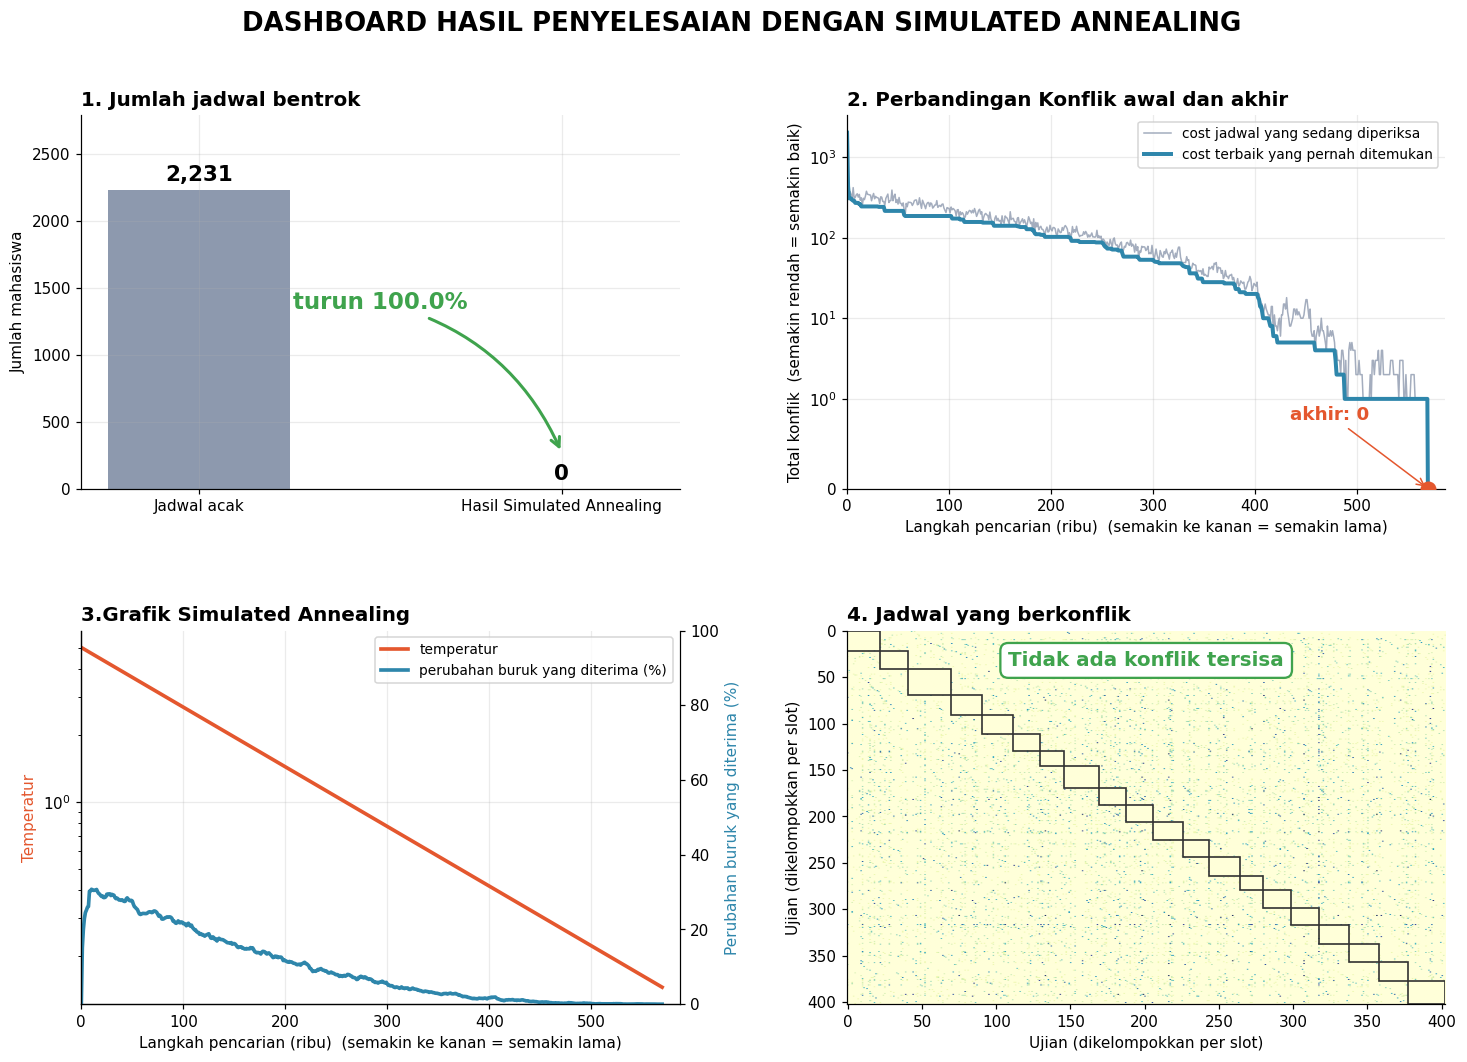

In [63]:
from IPython.display import HTML
from matplotlib.gridspec import GridSpec

schedule = np.asarray(hasil["schedule"])
total_mhs = len(students)

mhs_ujian = [[exam_index[int(v)] for v in row if not pd.isna(v)] for row in students.values]

def hitung_mhs_bentrok(jadwal):
    return sum(1 for ujian in mhs_ujian if len(set(jadwal[ujian])) != len(ujian))

bentrok_sa = hitung_mhs_bentrok(schedule)
bentrok_acak = int(np.mean([hitung_mhs_bentrok(random_schedule()) for _ in range(20)]))

same = schedule[:, None] == schedule[None, :]
idx_i, idx_j = np.where(np.triu((conflict > 0) & same, 1))

aman = total_mhs - bentrok_sa
persen_aman = aman / total_mhs * 100

if bentrok_sa == 0:
    kalimat = f"""
    Dari <b>{total_mhs:,}</b> mahasiswa, <b style="color:#3FA34D;">seluruhnya (100%)</b> tidak mengalami bentrok jadwal.<br>
    Jadwal <b style="color:#3FA34D;">yang bertabrakan</b> berhasil dihilangkan.<br>
   Dengan Perbandingan, jadwal yang dibuat dengan acak akan membuat sekitar <b>{bentrok_acak:,} mahasiswa</b> mengalami bentrok jadwal."""
else:
    kalimat = f"""
    Dari <b>{total_mhs:,}</b> mahasiswa, <b style="color:#3FA34D;">{aman:,} mahasiswa ({persen_aman:.2f}%)</b> tidak mengalami bentrok jadwal.<br>
    Hanya <b style="color:#E4572E;">{bentrok_sa} mahasiswa</b> yang masih punya dua ujian di waktu yang sama
    (pada {len(idx_i)} pasang ujian).<br>
    Sebagai pembanding, jadwal yang disusun acak akan membuat sekitar <b>{bentrok_acak:,} mahasiswa</b> bentrok."""

display(HTML(f"""
<div style="font-family:sans-serif; padding:18px 22px; border-radius:12px; background:#3FA34D15; border-left:8px solid #3FA34D; font-size:16px; line-height:1.6;">
    <div style="font-size:13px; color:#555; letter-spacing:1px;">KESIMPULAN</div>
    {kalimat}
</div>
"""))

def kartu(judul, nilai, ket, warna):
    return f"""
    <div style="flex:1; min-width:170px; padding:12px 16px; border-radius:10px; background:{warna}15; border-left:6px solid {warna};">
        <div style="font-size:12px; color:#555;">{judul}</div>
        <div style="font-size:26px; font-weight:bold; color:{warna};">{nilai}</div>
        <div style="font-size:12px; color:#777;">{ket}</div>
    </div>"""

display(HTML(f"""
<div style="display:flex; gap:12px; flex-wrap:wrap; font-family:sans-serif; margin-top:10px;">
    {kartu("Mahasiswa bentrok", f"{bentrok_sa}", f"jadwal acak: {bentrok_acak:,}", "#E4572E")}
    {kartu("Mahasiswa aman", f"{persen_aman:.2f}%", f"{aman:,} dari {total_mhs:,}", "#3FA34D")}
    {kartu("Ujian dijadwalkan", f"{n_exams}", f"ke dalam {NUM_SLOTS} slot waktu", "#2E86AB")}
    {kartu("Waktu proses", f"{waktu_sa:.0f} detik", f"{hasil['steps_done']:,} langkah pencarian", "#8D99AE")}
</div>
"""))

fig = plt.figure(figsize=(16, 10.5))
fig.patch.set_facecolor("white")
gs = GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.28)
fig.suptitle("DASHBOARD HASIL PENYELESAIAN DENGAN SIMULATED ANNEALING", fontsize=17, fontweight="bold", y=0.97)

ax1 = fig.add_subplot(gs[0, 0])
nilai = [bentrok_acak, bentrok_sa]
bar = ax1.bar(["Jadwal acak", "Hasil Simulated Annealing"], nilai, color=[WARNA["abu"], WARNA["hijau"]], width=0.5)
ax1.set_ylim(0, max(nilai) * 1.25)
ax1.set_ylabel("Jumlah mahasiswa")
ax1.set_title("1. Jumlah jadwal bentrok", loc="left", fontsize=13)
for b, v in zip(bar, nilai):
    ax1.text(b.get_x() + b.get_width() / 2, v + max(nilai) * 0.03, f"{v:,}", ha="center", fontweight="bold", fontsize=14)
turun_mhs = (1 - bentrok_sa / bentrok_acak) * 100
ax1.annotate(f"turun {turun_mhs:.1f}%", xy=(1, bentrok_sa + max(nilai) * 0.12), xytext=(0.5, max(nilai) * 0.6),
             ha="center", fontsize=15, fontweight="bold", color=WARNA["hijau"],
             arrowprops=dict(arrowstyle="->", lw=2, color=WARNA["hijau"], connectionstyle="arc3,rad=-0.25"))

ax2 = fig.add_subplot(gs[0, 1])
it = (np.array(hasil["log_iter"]) + 1) / 1000
cur = np.array(hasil["log_current"])
bst = np.array(hasil["history"])
ax2.plot(it, cur, color=WARNA["abu"], lw=1.0, alpha=0.8, label="cost jadwal yang sedang diperiksa")
ax2.plot(it, bst, color=WARNA["utama"], lw=2.6, label="cost terbaik yang pernah ditemukan")
ax2.set_yscale("symlog", linthresh=1)
ax2.set_ylim(bottom=0)
ax2.set_title("2. Perbandingan Konflik awal dan akhir", loc="left", fontsize=13)
ax2.set_xlabel("Langkah pencarian (ribu)  (semakin ke kanan = semakin lama)")
ax2.set_xlim(0, it[-1] * 1.03)
ax2.set_ylabel("Total konflik  (semakin rendah = semakin baik)")
ax2.scatter([it[-1]], [bst[-1]], color=WARNA["aksen"], s=90, zorder=5)
ax2.annotate(f"akhir: {bst[-1]}", xy=(it[-1], bst[-1]), xytext=(-90, 45), textcoords="offset points",
             color=WARNA["aksen"], fontweight="bold", fontsize=12, arrowprops=dict(arrowstyle="->", color=WARNA["aksen"]))
ax2.legend(loc="upper right", fontsize=9)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(it, hasil["log_temp"], color=WARNA["aksen"], lw=2.4, label="temperatur")
ax3.set_yscale("log")
ax3.set_xlim(0, it[-1] * 1.03)
ax3.set_xlabel("Langkah pencarian (ribu)  (semakin ke kanan = semakin lama)")
ax3.set_ylabel("Temperatur", color=WARNA["aksen"])
ax3.set_title("3.Grafik Simulated Annealing", loc="left", fontsize=13)
ax3b = ax3.twinx()
akseptasi = np.array(hasil["log_accept"]) * 100
ax3b.plot(it, pd.Series(akseptasi).rolling(8, min_periods=1).mean(), color=WARNA["utama"], lw=2.4, label="perubahan buruk yang diterima (%)")
ax3b.set_ylabel("Perubahan buruk yang diterima (%)", color=WARNA["utama"])
ax3b.set_ylim(0, 100)
ax3b.grid(False)
ax3b.spines["right"].set_visible(True)
h1, l1 = ax3.get_legend_handles_labels()
h2, l2 = ax3b.get_legend_handles_labels()
ax3.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)

ax4 = fig.add_subplot(gs[1, 1])
urut = np.argsort(schedule, kind="stable")
M = conflict[np.ix_(urut, urut)]
ax4.imshow(np.log1p(M), cmap="YlGnBu", aspect="auto", vmax=np.log1p(M).max() * 0.85)
jumlah_slot = np.bincount(schedule, minlength=NUM_SLOTS)
batas = np.cumsum(jumlah_slot)
awal = np.concatenate([[0], batas[:-1]])
for a, b in zip(awal, batas):
    if b > a:
        ax4.add_patch(Rectangle((a - 0.5, a - 0.5), b - a, b - a, fill=False, ec="#333", lw=1.1))
pos = np.empty(n_exams, dtype=int); pos[urut] = np.arange(n_exams)
if len(idx_i) > 0:
    ax4.scatter(pos[idx_j], pos[idx_i], s=70, color=WARNA["aksen"], edgecolor="black", lw=0.8, zorder=5,
                label=f"masih bentrok ({len(idx_i)} pasang ujian)")
    ax4.legend(loc="upper right", frameon=True)
else:
    ax4.text(0.5, 0.92, "Tidak ada konflik tersisa", transform=ax4.transAxes, ha="center", va="center",
             fontsize=13, fontweight="bold", color=WARNA["hijau"],
             bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=WARNA["hijau"], lw=1.5))
ax4.set_title("4. Jadwal yang berkonflik", loc="left", fontsize=13)
ax4.set_xlabel("Ujian (dikelompokkan per slot)"); ax4.set_ylabel("Ujian (dikelompokkan per slot)")
ax4.grid(False)

plt.show()